# Delivery Performance, Reviews and Retention: Olist Marketplace

**Data:** the public [Olist Brazilian E-Commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (real, anonymised orders from a Brazilian marketplace, Sep 2016 to Oct 2018, about 99,000 orders). Licence: CC BY-NC-SA 4.0.

**What this is not:** it is an e-commerce marketplace, not a food delivery company. I use it because it is real order data with delivery dates, promised dates and reviews, which are the same signals a delivery platform tracks.

**Questions**
1. How are orders, GMV and basket size trending?
2. How long does delivery take and how often is the promise missed?
3. Which states deliver worst?
4. Do late deliveries hurt reviews?
5. How many customers ever come back?
6. Does retention change by cohort?
7. Which categories drive revenue?
8. How concentrated are sellers?
9. Do customers with a late first order come back less?

All logic lives in `sql/`. This notebook runs the queries, draws a chart and writes down what the numbers say.

In [1]:
import sys, math
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
import utils, build_db

if not utils.DB.exists():
    build_db.main()

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

## 0. Data overview

In [2]:
import sqlite3
con = sqlite3.connect(utils.DB)
for t in ["orders", "customers", "order_items", "order_reviews", "products"]:
    print(f"{t:15s}", f"{con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]:>8,} rows")
print(con.execute("SELECT MIN(purchased_at), MAX(purchased_at) FROM order_facts").fetchone())
print(pd.read_sql_query("SELECT order_status, COUNT(*) AS orders FROM order_facts GROUP BY order_status ORDER BY orders DESC", con).to_string(index=False))

orders            99,441 rows
customers         99,441 rows
order_items      112,650 rows
order_reviews    100,000 rows
products          32,951 rows
('2016-09-04 21:15:19', '2018-10-17 17:30:18')
order_status  orders
   delivered   96478
     shipped    1107
    canceled     625
 unavailable     609
    invoiced     314
  processing     301
     created       5
    approved       2


`order_facts` (built in `sql/01_order_facts.sql`) has one row per order. Items and reviews are collapsed to one row per order **before** joining, otherwise multi-item orders would be counted several times and GMV would be inflated.

## Q1. Orders, GMV and basket size over time

,month,orders,gmv,aov,gmv_mom_pct
0,2017-01,787,136943.0,174.01,NaN
1,2017-02,1718,283562.0,165.05,107.1
2,2017-03,2617,425618.0,162.64,50.1
3,2017-04,2377,405849.0,170.74,-4.6
4,2017-05,3640,582711.0,160.09,43.6
5,2017-06,3205,499652.0,155.90,-14.3
6,2017-07,3946,578754.0,146.67,15.8
7,2017-08,4272,661904.0,154.94,14.4
8,2017-09,4227,717103.0,169.65,8.3
9,2017-10,4547,764756.0,168.19,6.6


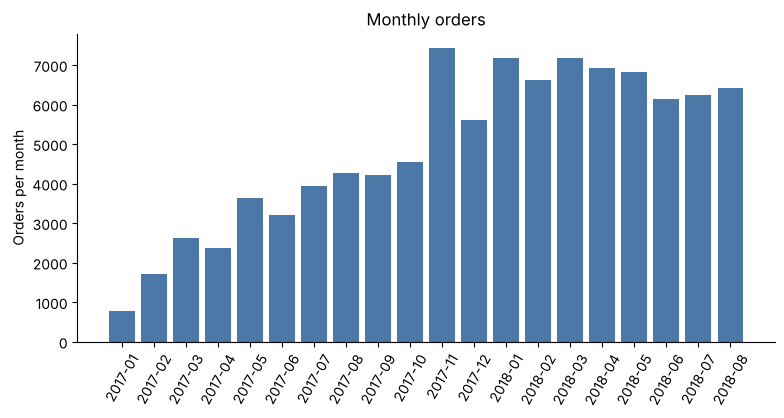

In [3]:
q1 = utils.run("q1_monthly_trend")
display(q1)
fig, ax = plt.subplots()
ax.bar(q1["month"], q1["orders"], color="#4C78A8")
ax.set_ylabel("Orders per month"); ax.set_title("Monthly orders")
plt.xticks(rotation=60); plt.show()

**Takeaway.** Orders grew about 9x from Jan 2017 (787) to Jan 2018 (7,187), then flattened at roughly 6,100 to 7,200 a month. November 2017 was the peak (7,421 orders, 1.17M BRL GMV, +53% on October). Average order value stayed in a narrow 147 to 174 BRL band, so growth came from more orders, not bigger baskets.

## Q2. Delivery time and missed promises by month

,month,delivered_orders,avg_delivery_days,late_pct
0,2017-01,750,12.6,3.1
1,2017-02,1653,13.2,3.2
2,2017-03,2546,13.0,5.6
3,2017-04,2303,14.9,7.9
4,2017-05,3545,11.3,3.6
5,2017-06,3135,12.0,3.9
6,2017-07,3872,11.6,3.4
7,2017-08,4193,11.1,3.3
8,2017-09,4150,11.9,5.2
9,2017-10,4478,11.9,5.3


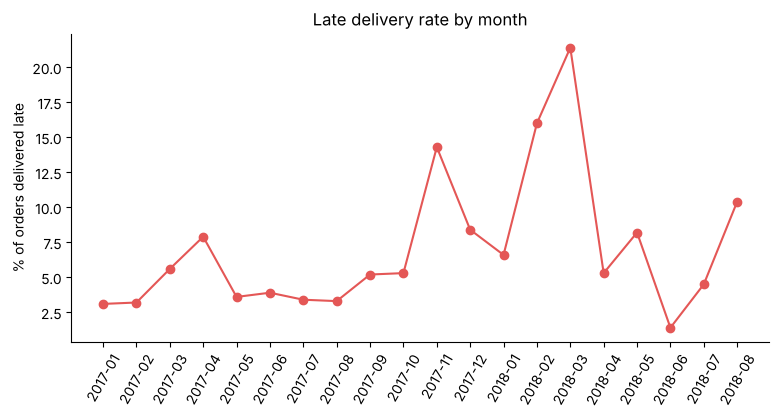

In [4]:
q2 = utils.run("q2_delivery_by_month")
display(q2)
fig, ax1 = plt.subplots()
ax1.plot(q2["month"], q2["late_pct"], color="#E45756", marker="o")
ax1.set_ylabel("% of orders delivered late"); ax1.set_title("Late delivery rate by month")
plt.xticks(rotation=60); plt.show()

**Takeaway.** Late delivery is spiky. It jumped to 14.3% in Nov 2017 (the order peak) but also hit 16.0% in Feb 2018 and 21.4% in Mar 2018, months without an order spike, so volume alone does not explain it. By Jun 2018 it was 1.4%. Average delivery time fell from 15.4 days (Dec 2017) to 7.7 days (Aug 2018). The data cannot tell us why; it only shows where to look.

## Q3. Delivery performance by state

,state,delivered_orders,avg_delivery_days,late_pct,avg_review
0,MA,717,21.6,19.7,3.81
1,CE,1279,21.3,15.3,3.94
2,BA,3256,19.3,14.0,3.91
3,RJ,12353,15.3,13.5,3.95
4,PA,946,23.8,12.4,3.89
5,ES,1995,15.8,12.2,4.05
6,MS,701,15.6,11.6,4.16
7,PB,517,20.4,11.0,4.06
8,PE,1593,18.4,10.8,4.07
9,SC,3547,15.0,9.8,4.12


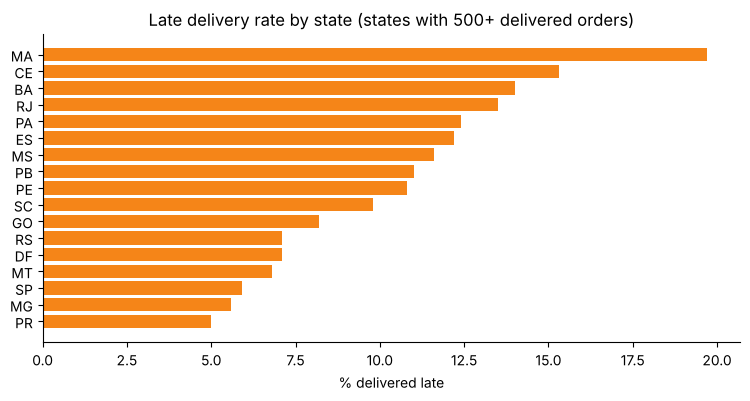

In [5]:
q3 = utils.run("q3_delivery_by_state")
display(q3)
fig, ax = plt.subplots()
ax.barh(q3["state"][::-1], q3["late_pct"][::-1], color="#F58518")
ax.set_xlabel("% delivered late"); ax.set_title("Late delivery rate by state (states with 500+ delivered orders)")
plt.show()

**Takeaway.** São Paulo (SP) is both the biggest market (40,495 delivered orders) and one of the best performers (8.8 days, 5.9% late). The worst late rates are in MA (19.7%), CE (15.3%), BA (14.0%) and RJ (13.5%). RJ is notable because it is the second-largest market. MA has the lowest average review of the group (3.81 vs 4.23 in SP).

## Q4. Do late deliveries hurt reviews?

,delivery_bucket,orders,avg_review,low_review_pct
0,1. On time or early,88649,4.28,9.5
1,2. 1-3 days late,2662,3.75,19.5
2,3. 4-7 days late,1819,2.30,61.8
3,4. 8+ days late,3346,1.72,78.5


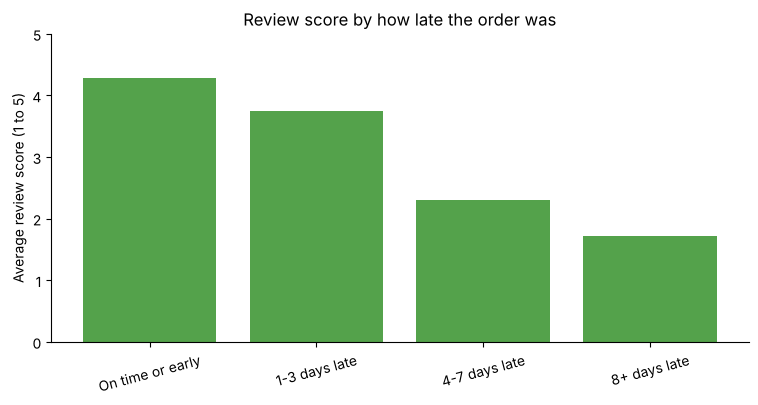

In [6]:
q4 = utils.run("q4_late_vs_review")
display(q4)
fig, ax = plt.subplots()
ax.bar(q4["delivery_bucket"].str[3:], q4["avg_review"], color="#54A24B")
ax.set_ylabel("Average review score (1 to 5)"); ax.set_title("Review score by how late the order was")
ax.set_ylim(0, 5); plt.xticks(rotation=15); plt.show()

**Takeaway.** Reviews fall sharply with lateness. On-time orders average 4.28 stars, with 9.5% scoring 1 or 2. Orders 1 to 3 days late average 3.75 (19.5% low), 4 to 7 days late average 2.30 (61.8% low), and beyond a week late they average 1.72 with 78.5% low scores. The damage is steepest after about 3 days. This is a correlation: late orders may also have had other problems.

## Q5. How many customers come back?

In [7]:
q5 = utils.run("q5_repeat_customers")
display(q5)

,customers,repeat_customers,repeat_pct
0,94990,2888,3.04


**Takeaway.** Only 3.04% of customers (2,888 of 94,990) placed a second order. This is a one-and-done marketplace, which makes acquisition cost and first-order experience the main levers.

## Q6. Do cohorts differ in how many return within 90 days?

,cohort_month,new_customers,returned_within_90d,return_pct
0,2017-01,752,29,3.86
1,2017-02,1690,31,1.83
2,2017-03,2571,66,2.57
3,2017-04,2325,50,2.15
4,2017-05,3541,102,2.88
5,2017-06,3102,89,2.87
6,2017-07,3822,101,2.64
7,2017-08,4130,114,2.76
8,2017-09,4075,121,2.97
9,2017-10,4392,102,2.32


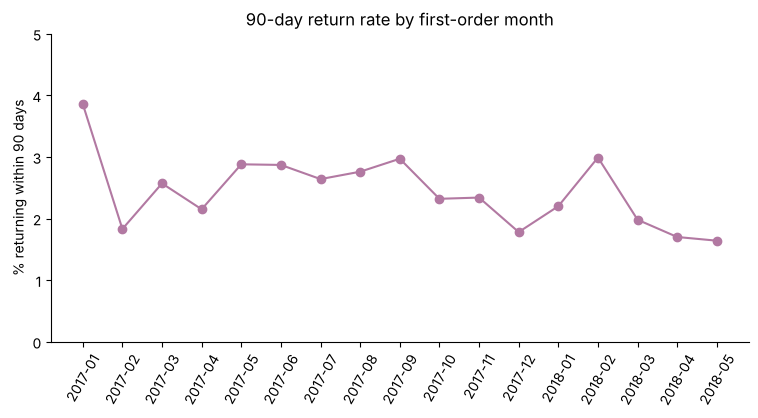

In [8]:
q6 = utils.run("q6_cohort_90d_return")
display(q6)
fig, ax = plt.subplots()
ax.plot(q6["cohort_month"], q6["return_pct"], marker="o", color="#B279A2")
ax.set_ylabel("% returning within 90 days"); ax.set_ylim(0, 5); ax.set_title("90-day return rate by first-order month")
plt.xticks(rotation=60); plt.show()

**Takeaway.** Return rates stay between 1.6% and 3.9% in every cohort, with no sign of improvement. The highest value (3.86%, Jan 2017) comes from a small cohort of 752 customers, so it should not be over-read. The latest cohort (May 2018) is the lowest at 1.64%.

## Q7. Which categories drive revenue?

In [9]:
q7 = utils.run("q7_top_categories")
display(q7)

,category,orders,revenue,share_pct,cumulative_share_pct
0,health_beauty,8836,1258681.0,9.3,9.3
1,watches_gifts,5624,1205006.0,8.9,18.1
2,bed_bath_table,9417,1036989.0,7.6,25.8
3,sports_leisure,7720,988049.0,7.3,33.0
4,computers_accessories,6689,911954.0,6.7,39.7
5,furniture_decor,6449,729762.0,5.4,45.1
6,cool_stuff,3632,635291.0,4.7,49.8
7,housewares,5884,632249.0,4.7,54.4
8,auto,3897,592720.0,4.4,58.8
9,garden_tools,3518,485256.0,3.6,62.4


**Takeaway.** Revenue is spread across categories. The largest, health_beauty, is only 9.3% of item revenue, and the top 10 categories together make up 62.4%. There is no single category to protect.

## Q8. Seller concentration

,decile,sellers,revenue,share_pct
0,1,310,9183175.0,67.6
1,2,310,2060449.0,15.2
2,3,310,1033680.0,7.6
3,4,310,550185.0,4.0
4,5,310,328924.0,2.4
5,6,309,202310.0,1.5
6,7,309,116479.0,0.9
7,8,309,66790.0,0.5
8,9,309,36033.0,0.3
9,10,309,13618.0,0.1


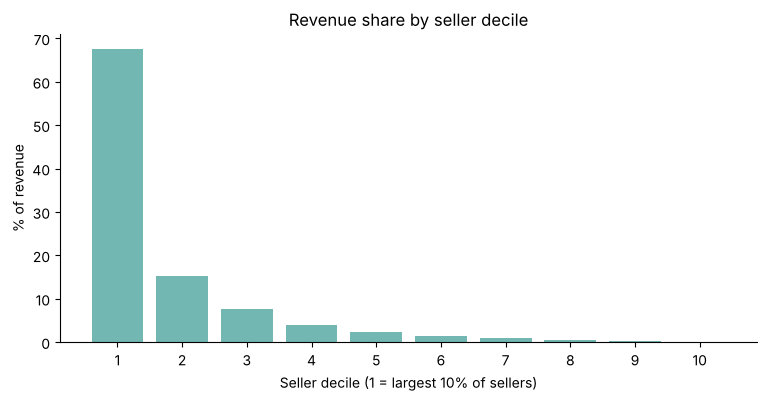

In [10]:
q8 = utils.run("q8_seller_concentration")
display(q8)
fig, ax = plt.subplots()
ax.bar(q8["decile"].astype(str), q8["share_pct"], color="#72B7B2")
ax.set_xlabel("Seller decile (1 = largest 10% of sellers)"); ax.set_ylabel("% of revenue")
ax.set_title("Revenue share by seller decile"); plt.show()

**Takeaway.** Supply is very concentrated. The top 10% of sellers (310) earn 67.6% of revenue and the top 20% earn about 83%, while the bottom half earn about 3% combined. Losing a handful of large sellers would matter far more than losing many small ones.

## Q9. Do customers with a late first order return less?

In [11]:
q9 = utils.run("q9_first_order_experience")
display(q9)

# two-proportion z-test
on_time = q9[q9["first_order"] == "First order on time"].iloc[0]
late = q9[q9["first_order"] == "First order late"].iloc[0]
p1, n1 = on_time["return_within_90d_pct"] / 100, on_time["customers"]
p2, n2 = late["return_within_90d_pct"] / 100, late["customers"]
p = (p1 * n1 + p2 * n2) / (n1 + n2)
z = (p1 - p2) / math.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
print(f"difference = {100*(p1-p2):.2f} percentage points, z = {z:.2f}")

,first_order,customers,return_within_90d_pct
0,First order on time,68478,2.32
1,First order late,6598,2.08


difference = 0.24 percentage points, z = 1.24


**Takeaway.** Customers whose first order was late returned at 2.08%, versus 2.32% for on-time first orders. The gap is 0.24 percentage points and the z-statistic is 1.24, which is not statistically significant at the usual 5% level. So late delivery clearly hurts reviews (Q4), but it does not explain why retention is so low: even customers with a smooth first order rarely come back.

## Summary

- Growth came from order volume, not basket size, and plateaued after Jan 2018.
- Delivery reliability varies a lot by month and by state; the Northeast and RJ are weakest.
- Late delivery strongly lowers review scores, especially beyond 3 days.
- Retention is very low (about 3%) and is **not** explained by late first deliveries in this data.
- Revenue is spread across categories but concentrated in a small set of sellers.

**Limits.** One marketplace, one country, 2016 to 2018, no customer acquisition cost, no repeat behaviour on other channels. The reviews analysis is correlational. A good next step would be an experiment on post-purchase engagement, since delivery alone does not move repeat rate.